# Lab 07 Solutions

In [1]:
import os
import time
import glob
import numpy as np
import cv2
import matplotlib.pyplot as plt

os.makedirs("output", exist_ok=True)
sample = cv2.imread("images/sample.jpg")


def show(ax, im, title=""):
    ax.imshow(im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_BGR2RGB), cmap="gray")
    ax.set_title(title)
    ax.axis("off")


def poly_area(pts):
    pts = np.asarray(pts, float)
    x, y = pts[:, 0], pts[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


def order_points(pts):
    pts = np.asarray(pts, np.float32).reshape(4, 2)
    s = pts.sum(axis=1)
    d = np.diff(pts, axis=1).ravel()
    return np.float32([pts[np.argmin(s)], pts[np.argmin(d)], pts[np.argmax(s)], pts[np.argmax(d)]])


def find_quad(image):
    g = cv2.GaussianBlur(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    _, th = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
    cs, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    c = max(cs, key=cv2.contourArea)
    approx = cv2.approxPolyDP(c, 0.02 * cv2.arcLength(c, True), True)
    if len(approx) != 4:
        approx = cv2.boxPoints(cv2.minAreaRect(c))
    return order_points(approx)


def quad_size(q):
    tl, tr, br, bl = q
    w = int(max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl)))
    h = int(max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr)))
    return w, h


## Q1 (a) 2D transformations

Transform                   area ratio    det(A)  corner angle
Translation (+140, +90)          1.000     1.000          90.0
Rotation 25 deg                  1.000     1.000          90.0
Scaling (1.4, 0.7)               0.980     0.980          90.0
Shear x 0.35                     1.000     1.000          70.7
Shear y 0.30                     1.000     1.000          73.3


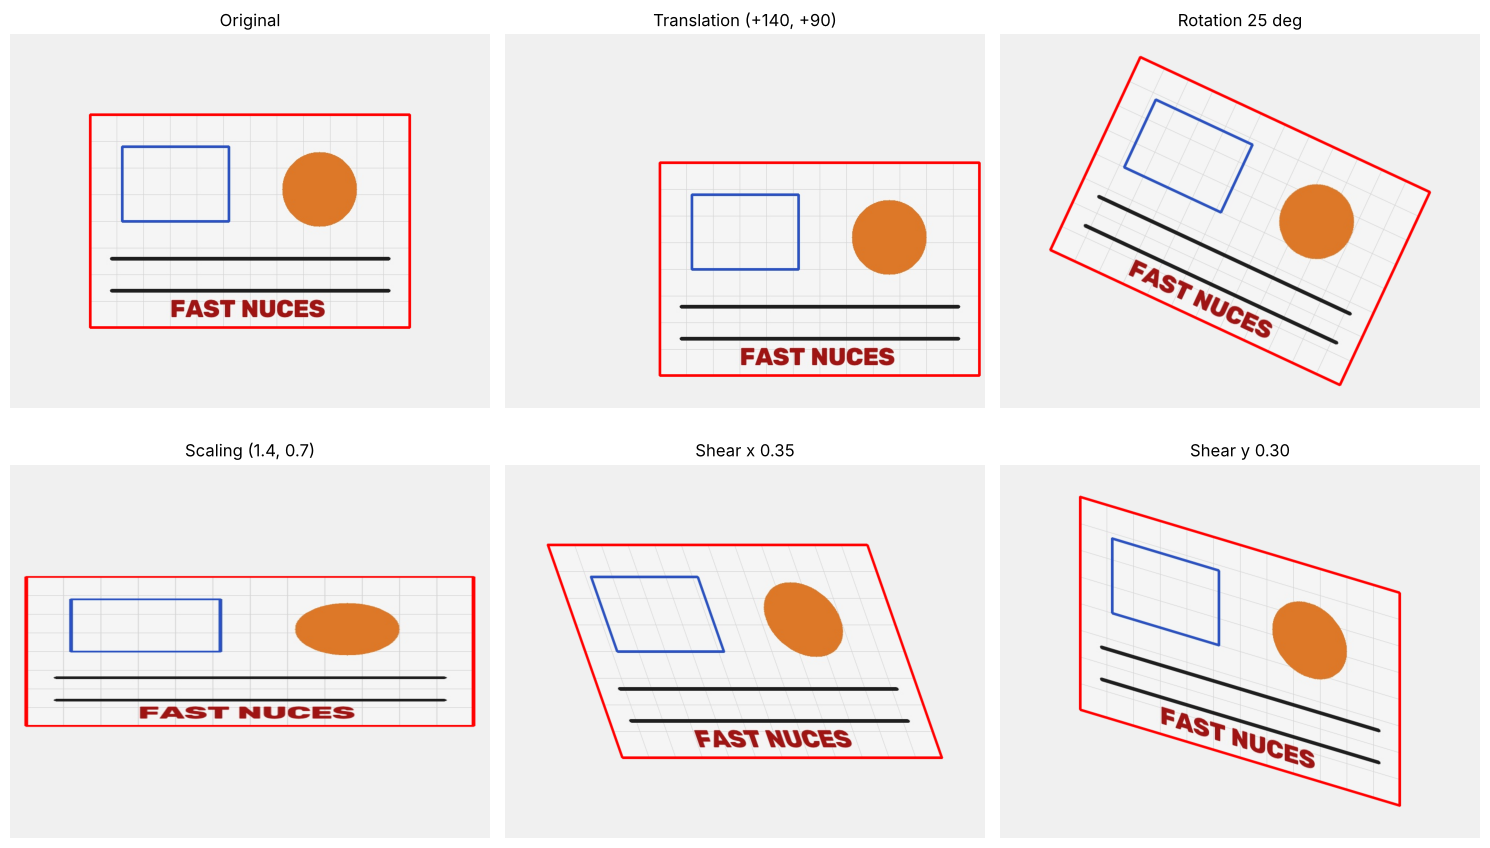

In [2]:
sh, sw = sample.shape[:2]
CW, CH = 900, 700
ox, oy = (CW - sw) // 2, (CH - sh) // 2
base = np.full((CH, CW, 3), 240, np.uint8)
base[oy:oy + sh, ox:ox + sw] = sample
cv2.rectangle(base, (ox, oy), (ox + sw - 1, oy + sh - 1), (0, 0, 255), 3)
box = np.float32([[ox, oy], [ox + sw, oy], [ox + sw, oy + sh], [ox, oy + sh]])
cx, cy = CW / 2, CH / 2


def about_centre(M):
    C = np.array([[1, 0, cx], [0, 1, cy], [0, 0, 1]], float)
    Ci = np.array([[1, 0, -cx], [0, 1, -cy], [0, 0, 1]], float)
    return C @ M @ Ci


def rot2(deg):
    a = np.deg2rad(deg)
    return np.array([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]])


transforms = {
    "Translation (+140, +90)": np.array([[1, 0, 140], [0, 1, 90], [0, 0, 1]], float),
    "Rotation 25 deg": about_centre(rot2(25)),
    "Scaling (1.4, 0.7)": about_centre(np.diag([1.4, 0.7, 1.0])),
    "Shear x 0.35": about_centre(np.array([[1, 0.35, 0], [0, 1, 0], [0, 0, 1]], float)),
    "Shear y 0.30": about_centre(np.array([[1, 0, 0], [0.30, 1, 0], [0, 0, 1]], float)),
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
show(axes[0, 0], base, "Original")
a0 = poly_area(box)
print(f"{'Transform':26s}{'area ratio':>12s}{'det(A)':>10s}{'corner angle':>14s}")
for ax, (name, M) in zip(axes.ravel()[1:], transforms.items()):
    moved_img = cv2.warpAffine(base, M[:2], (CW, CH), borderValue=(240, 240, 240))
    moved = cv2.perspectiveTransform(box.reshape(-1, 1, 2), M).reshape(-1, 2)
    v1, v2 = moved[1] - moved[0], moved[3] - moved[0]
    ang = np.degrees(np.arccos(np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))))
    print(f"{name:26s}{poly_area(moved) / a0:12.3f}{np.linalg.det(M[:2, :2]):10.3f}{ang:14.1f}")
    show(ax, moved_img, name)
plt.tight_layout()
plt.savefig("output/q1a_2d_transforms.png", dpi=120)
plt.show()


## Q1 (b) 3D transformation

Original                   centroid [1.333 1.333 0.6  ]  max edge-length change 0.00e+00
Rotate 40 deg about x      centroid [1.333 1.333 0.6  ]  max edge-length change 4.44e-16
Rotate 40 deg about y      centroid [1.333 1.333 0.6  ]  max edge-length change 4.44e-16
Rotate 40 deg about z      centroid [1.333 1.333 0.6  ]  max edge-length change 4.44e-16
Translate (2, -1, 3)       centroid [3.333 0.333 3.6  ]  max edge-length change 2.22e-16
Rotate xyz + translate     centroid [3.333 0.333 3.6  ]  max edge-length change 4.44e-16


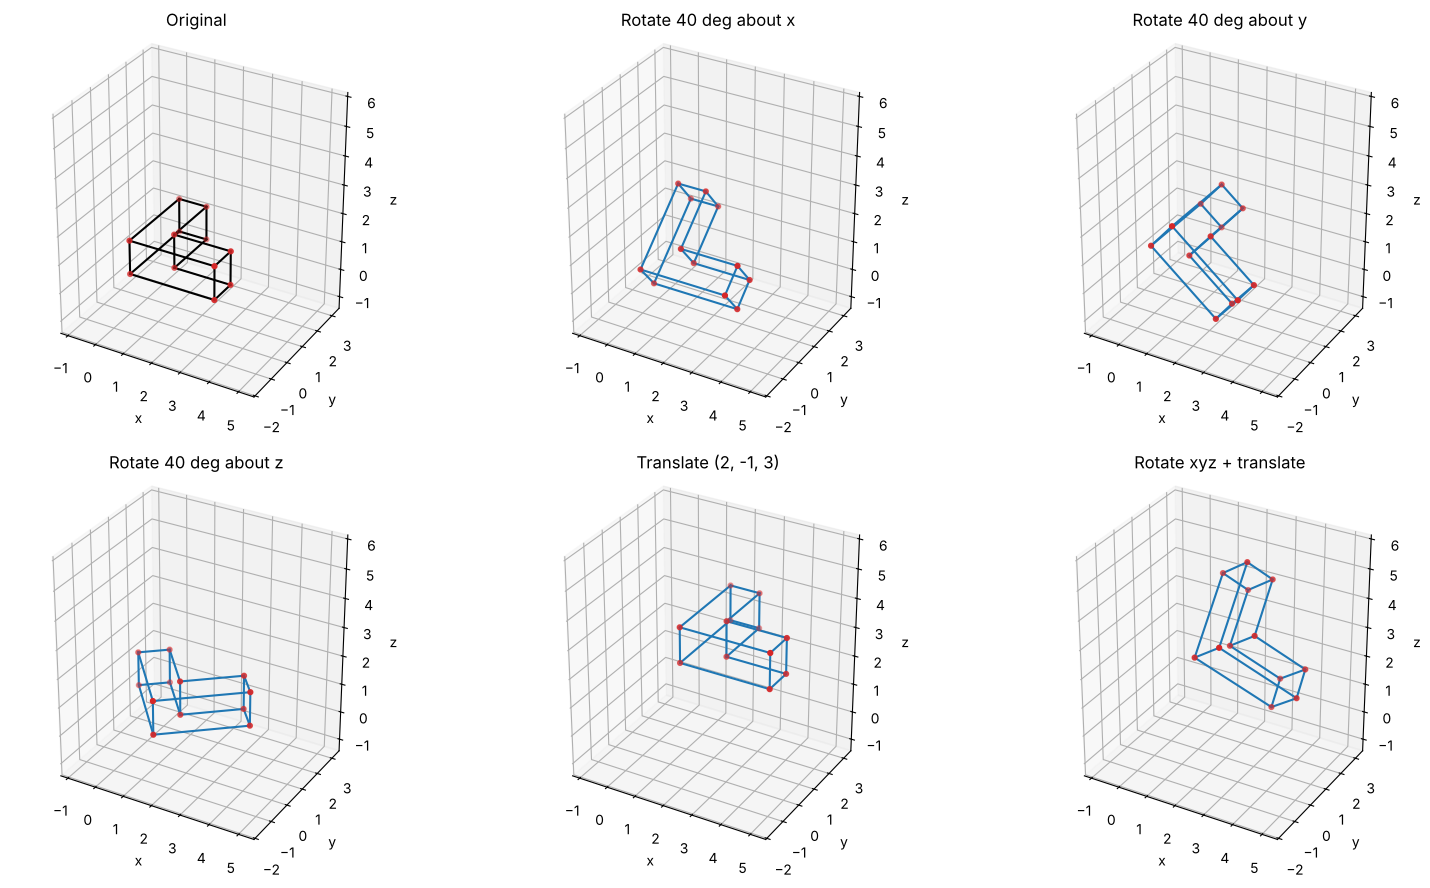

Combined 4x4 homogeneous matrix:
 [[ 0.5868 -0.1759  0.7904  2.3112]
 [ 0.4924  0.8524 -0.1759 -1.3542]
 [-0.6428  0.4924  0.5868  3.4484]
 [ 0.      0.      0.      1.    ]]


In [3]:
L = np.array([[0, 0], [3, 0], [3, 1], [1, 1], [1, 3], [0, 3]], float)
height = 1.2
n = len(L)
V = np.vstack([np.c_[L, np.zeros(n)], np.c_[L, np.full(n, height)]])
E = [(i, (i + 1) % n) for i in range(n)]
E += [(n + i, n + (i + 1) % n) for i in range(n)]
E += [(i, n + i) for i in range(n)]
Vh = np.c_[V, np.ones(len(V))]
centroid = V.mean(axis=0)


def mat4(R3=None, t=(0, 0, 0)):
    M = np.eye(4)
    if R3 is not None:
        M[:3, :3] = R3
    M[:3, 3] = t
    return M


def rot3(axis, deg):
    v = np.zeros(3)
    v["xyz".index(axis)] = np.deg2rad(deg)
    return cv2.Rodrigues(v)[0]


def about_c(M):
    return mat4(t=centroid) @ M @ mat4(t=-centroid)


combined_R = rot3("z", 40) @ rot3("y", 40) @ rot3("x", 40)
variants = [
    ("Original", np.eye(4)),
    ("Rotate 40 deg about x", about_c(mat4(rot3("x", 40)))),
    ("Rotate 40 deg about y", about_c(mat4(rot3("y", 40)))),
    ("Rotate 40 deg about z", about_c(mat4(rot3("z", 40)))),
    ("Translate (2, -1, 3)", mat4(t=(2, -1, 3))),
    ("Rotate xyz + translate", mat4(t=(2, -1, 3)) @ about_c(mat4(combined_R))),
]

moved_sets = [(name, (M @ Vh.T).T[:, :3]) for name, M in variants]
allp = np.vstack([p for _, p in moved_sets])
lo, hi = allp.min(axis=0) - 0.5, allp.max(axis=0) + 0.5
edge_len = lambda P: np.array([np.linalg.norm(P[i] - P[j]) for i, j in E])

fig = plt.figure(figsize=(16, 9))
for k, (name, P) in enumerate(moved_sets):
    ax = fig.add_subplot(2, 3, k + 1, projection="3d")
    for i, j in E:
        ax.plot3D(*zip(P[i], P[j]), color="tab:blue" if k else "black")
    ax.scatter(*P.T, s=12, color="tab:red")
    ax.set_xlim(lo[0], hi[0])
    ax.set_ylim(lo[1], hi[1])
    ax.set_zlim(lo[2], hi[2])
    ax.set_box_aspect(hi - lo)
    ax.set_title(name)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    print(f"{name:26s} centroid {np.round(P.mean(axis=0), 3)}  max edge-length change {np.abs(edge_len(P) - edge_len(V)).max():.2e}")
plt.tight_layout()
plt.savefig("output/q1b_3d_transforms.png", dpi=120)
plt.show()
print("Combined 4x4 homogeneous matrix:\n", np.round(variants[-1][1], 4))


## Q1 (c) Homogeneous coordinates

In [4]:
p = np.array([4.0, 3.0])
ph = np.append(p, 1.0)
print("Cartesian point:", p, "| homogeneous:", ph)
print("Same point written with w = 3:", 3 * ph, "-> divide by w:", (3 * ph)[:2] / (3 * ph)[2])

t = np.array([6.0, -2.0])
Th = np.array([[1, 0, t[0]], [0, 1, t[1]], [0, 0, 1]])
print("Translation as 3x3 product:", (Th @ ph)[:2], "| expected", p + t)

Rm = np.array([[0, -1, 0], [1, 0, 0], [0, 0, 1.0]])
Sm = np.diag([2.0, 2.0, 1.0])
M = Th @ Sm @ Rm
stepwise = Th @ (Sm @ (Rm @ ph))
print("Rotate 90, scale 2, translate in one matrix:\n", M)
print("One matrix result:", (M @ ph)[:2], "| step by step:", stepwise[:2], "| equal:", np.allclose(M @ ph, stepwise))

P = np.array([[1, 0, 0], [0, 1, 0], [0.002, 0.001, 1.0]])
q = P @ ph
print("Projective matrix output:", np.round(q, 4), "-> after dividing by w:", np.round(q[:2] / q[2], 4))

d = np.array([1.0, 2.0, 0.0])
print("Direction with w = 0 after translation:", Th @ d, "(unchanged, translation does not move directions)")
print("The extra coordinate turns translation into a matrix product, lets every transform combine into one matrix, and gives perspective its division by w.")


Cartesian point: [4. 3.] | homogeneous: [4. 3. 1.]
Same point written with w = 3: [12.  9.  3.] -> divide by w: [4. 3.]
Translation as 3x3 product: [10.  1.] | expected [10.  1.]
Rotate 90, scale 2, translate in one matrix:
 [[ 0. -2.  6.]
 [ 2.  0. -2.]
 [ 0.  0.  1.]]
One matrix result: [0. 6.] | step by step: [0. 6.] | equal: True
Projective matrix output: [4.    3.    1.011] -> after dividing by w: [3.9565 2.9674]
Direction with w = 0 after translation: [1. 2. 0.] (unchanged, translation does not move directions)
The extra coordinate turns translation into a matrix product, lets every transform combine into one matrix, and gives perspective its division by w.


## Q1 (d) Affine transformation

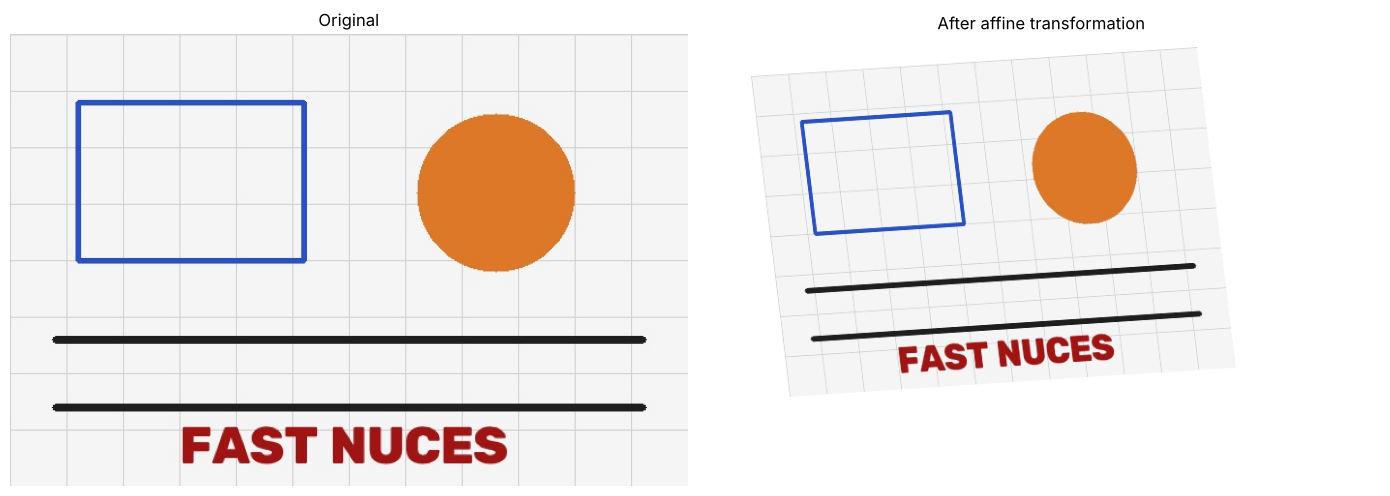

Affine matrix A:
 [[ 0.7679  0.1003 50.    ]
 [-0.0501  0.8271 40.    ]]
Straightness residual of the two lines after transform: [0. 0.]
Direction of the two parallel lines after transform: [ 0.9979 -0.0651] [ 0.9979 -0.0651] | cross product: -0.0
Length ratio of a midpoint before / after: 0.5 0.5
Right angle at the image corner becomes: 86.82 degrees
Area scale factor det(A): 0.6402
Straight lines remain straight: True
Parallel lines remain parallel: True


In [5]:
sh, sw = sample.shape[:2]
src3 = np.float32([[0, 0], [sw - 1, 0], [0, sh - 1]])
dst3 = np.float32([[50, 40], [sw - 90, 10], [90, sh - 30]])
A = cv2.getAffineTransform(src3, dst3)
affine_img = cv2.warpAffine(sample, A, (sw + 100, sh + 60), borderValue=(255, 255, 255))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
show(axes[0], sample, "Original")
show(axes[1], affine_img, "After affine transformation")
plt.tight_layout()
plt.savefig("output/q1d_affine.png", dpi=120)
plt.show()

A3 = np.vstack([A, [0, 0, 1]])


def apply_pts(pts):
    return (A3 @ np.c_[pts, np.ones(len(pts))].T).T[:, :2]


xs = np.linspace(40, 560, 60)
line1 = np.c_[xs, np.full_like(xs, 270.0)]
line2 = np.c_[xs, np.full_like(xs, 330.0)]
t1, t2 = apply_pts(line1), apply_pts(line2)


def straight_residual(P):
    c = np.polyfit(P[:, 0], P[:, 1], 1)
    return np.abs(np.polyval(c, P[:, 0]) - P[:, 1]).max()


d1 = (t1[-1] - t1[0]) / np.linalg.norm(t1[-1] - t1[0])
d2 = (t2[-1] - t2[0]) / np.linalg.norm(t2[-1] - t2[0])
mid_before = line1[len(xs) // 2 - 1:len(xs) // 2 + 1].mean(axis=0)
mid_after = apply_pts(mid_before[None])[0]
ratio_after = np.linalg.norm(mid_after - t1[0]) / np.linalg.norm(t1[-1] - t1[0])
ratio_before = np.linalg.norm(mid_before - line1[0]) / np.linalg.norm(line1[-1] - line1[0])
corner = np.float32([[0, 0], [sw, 0], [0, sh]])
cm = apply_pts(corner)
va, vb = cm[1] - cm[0], cm[2] - cm[0]
angle_after = np.degrees(np.arccos(np.dot(va, vb) / (np.linalg.norm(va) * np.linalg.norm(vb))))

print("Affine matrix A:\n", np.round(A, 4))
print("Straightness residual of the two lines after transform:", np.round([straight_residual(t1), straight_residual(t2)], 10))
print("Direction of the two parallel lines after transform:", np.round(d1, 4), np.round(d2, 4), "| cross product:", round(float(d1[0] * d2[1] - d1[1] * d2[0]), 10))
print("Length ratio of a midpoint before / after:", round(float(ratio_before), 4), round(float(ratio_after), 4))
print("Right angle at the image corner becomes:", round(float(angle_after), 2), "degrees")
print("Area scale factor det(A):", round(float(np.linalg.det(A[:, :2])), 4))
print("Straight lines remain straight:", bool(max(straight_residual(t1), straight_residual(t2)) < 1e-6))
print("Parallel lines remain parallel:", bool(abs(d1[0] * d2[1] - d1[1] * d2[0]) < 1e-9))


## Q1 (e) Projective transformation (homography)

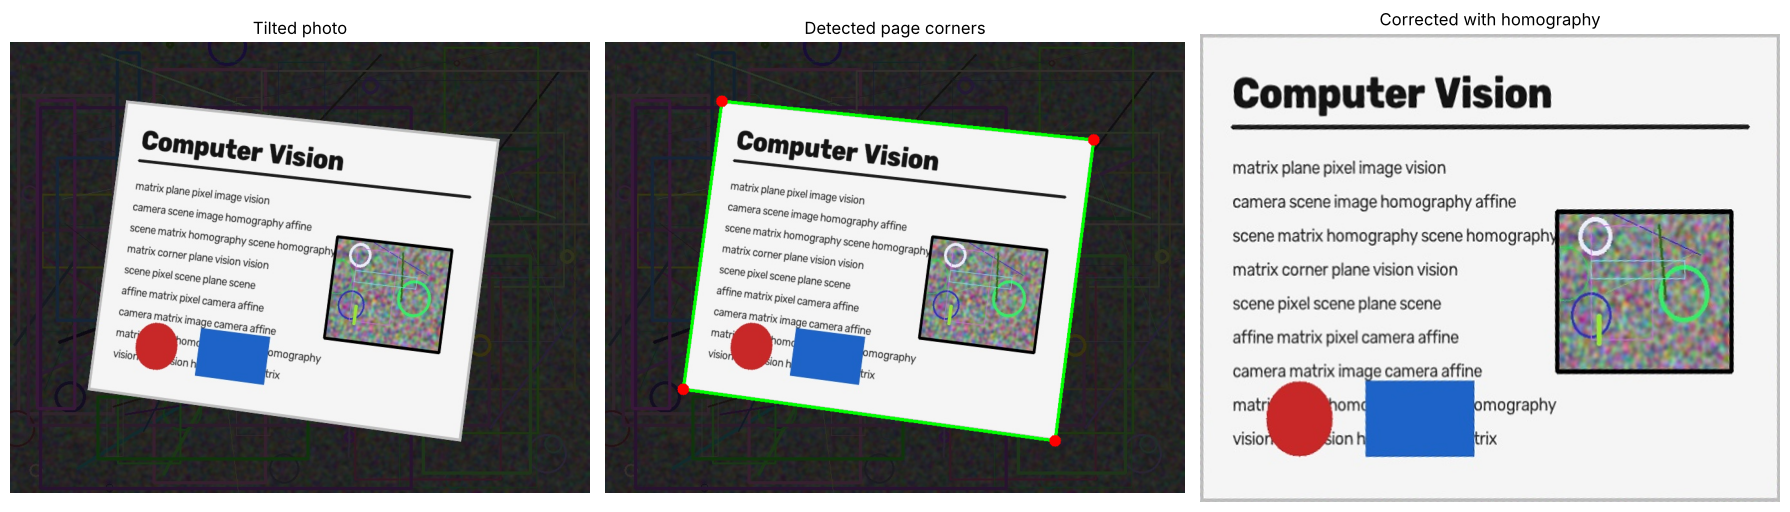

Detected corners (TL, TR, BR, BL):
 [[181.  91.]
 [758. 151.]
 [698. 618.]
 [121. 538.]]
Homography matrix:
 [[ 1.0527000e+00  1.4130000e-01 -2.0339714e+02]
 [-1.0974000e-01  1.0553700e+00 -7.6174990e+01]
 [ 8.0000000e-05  2.0000000e-05  1.0000000e+00]]
Output size: (582, 470)
Top and bottom page edges differ by 1.96 degrees in the photo (parallel on the real page)
Corner error against the known page position (px): [1.41 2.24 2.83 2.24]
Mean absolute difference from the true flat page: 6.66 / 255


In [6]:
book = cv2.imread("images/book_tilted.jpg")
flat_reference = cv2.imread("images/book_flat_reference.jpg")
true_quad = np.float32([[180, 90], [760, 150], [700, 620], [120, 540]])

corners = find_quad(book)
wd, hd = quad_size(corners)
target = np.float32([[0, 0], [wd - 1, 0], [wd - 1, hd - 1], [0, hd - 1]])
Hm = cv2.getPerspectiveTransform(corners, target)
flat = cv2.warpPerspective(book, Hm, (wd, hd), flags=cv2.INTER_CUBIC)

marked = book.copy()
cv2.polylines(marked, [np.int32(corners)], True, (0, 255, 0), 4)
for pt in corners:
    cv2.circle(marked, tuple(int(v) for v in pt), 9, (0, 0, 255), -1)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
show(axes[0], book, "Tilted photo")
show(axes[1], marked, "Detected page corners")
show(axes[2], flat, "Corrected with homography")
plt.tight_layout()
plt.savefig("output/q1e_homography.png", dpi=120)
plt.show()
cv2.imwrite("output/q1e_flat_book.jpg", flat)

top = corners[1] - corners[0]
bottom = corners[2] - corners[3]
angle_between = np.degrees(np.arccos(np.dot(top, bottom) / (np.linalg.norm(top) * np.linalg.norm(bottom))))
corner_err = np.linalg.norm(corners - true_quad, axis=1)
mae = np.mean(cv2.absdiff(cv2.resize(flat, (700, 500)), flat_reference))
print("Detected corners (TL, TR, BR, BL):\n", np.round(corners, 1))
print("Homography matrix:\n", np.round(Hm, 5))
print("Output size:", (wd, hd))
print("Top and bottom page edges differ by", round(float(angle_between), 2), "degrees in the photo (parallel on the real page)")
print("Corner error against the known page position (px):", np.round(corner_err, 2))
print("Mean absolute difference from the true flat page:", round(float(mae), 2), "/ 255")


## Q2 Perspective correction (unwarping)

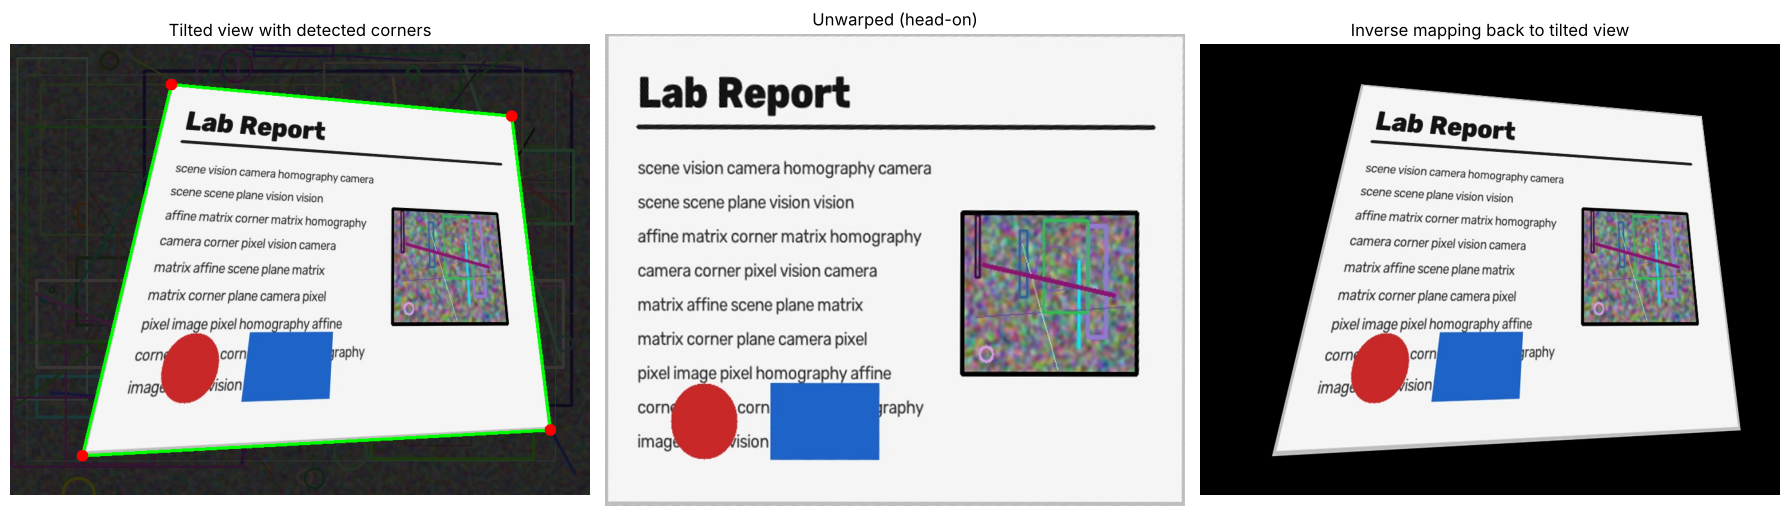

Source corners (tilted view, TL TR BR BL):
 [[250.  62.]
 [778. 111.]
 [838. 598.]
 [112. 638.]]
Destination corners (rectangle):
 [[  0.   0.]
 [726.   0.]
 [726. 591.]
 [  0. 591.]]
Perspective matrix M:
 [[ 1.1145600e+00  2.6703000e-01 -2.9519472e+02]
 [-1.2530000e-01  1.3501500e+00 -5.2384980e+01]
 [-3.1000000e-04  5.9000000e-04  1.0000000e+00]]
Output size: (727, 592)
Mean absolute difference from the true flat page: 8.11 / 255
Round trip error inside the page after the inverse mapping: 0.73 / 255


In [7]:
def apply_perspective_transform(image, src_points, dst_points, output_size):
    M = cv2.getPerspectiveTransform(np.float32(src_points), np.float32(dst_points))
    return cv2.warpPerspective(image, M, output_size, flags=cv2.INTER_CUBIC), M


def unwarp_document(image):
    tilted_quad = find_quad(image)
    width, height = quad_size(tilted_quad)
    rectangle = np.float32([[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]])
    flat_image, M = apply_perspective_transform(image, tilted_quad, rectangle, (width, height))
    return flat_image, M, tilted_quad, rectangle


tilted = cv2.imread("images/doc_tilted.jpg")
flat_reference = cv2.imread("images/doc_flat_reference.jpg")
corrected, M, tilted_quad, rectangle = unwarp_document(tilted)

restored = cv2.warpPerspective(corrected, np.linalg.inv(M), (tilted.shape[1], tilted.shape[0]), flags=cv2.INTER_CUBIC)
inside = np.zeros(tilted.shape[:2], np.uint8)
cv2.fillPoly(inside, [np.int32(tilted_quad)], 255)
inside = cv2.erode(inside, np.ones((7, 7), np.uint8)) > 0

marked = tilted.copy()
cv2.polylines(marked, [np.int32(tilted_quad)], True, (0, 255, 0), 4)
for pt in tilted_quad:
    cv2.circle(marked, tuple(int(v) for v in pt), 9, (0, 0, 255), -1)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
show(axes[0], marked, "Tilted view with detected corners")
show(axes[1], corrected, "Unwarped (head-on)")
show(axes[2], restored, "Inverse mapping back to tilted view")
plt.tight_layout()
plt.savefig("output/q2_unwarp.png", dpi=120)
plt.show()
cv2.imwrite("output/q2_unwarped_document.jpg", corrected)
cv2.imwrite("output/q2_tilted_document.jpg", tilted)

mae_flat = np.mean(cv2.absdiff(cv2.resize(corrected, (700, 500)), flat_reference))
mae_back = np.mean(cv2.absdiff(restored, tilted)[inside])
print("Source corners (tilted view, TL TR BR BL):\n", np.round(tilted_quad, 1))
print("Destination corners (rectangle):\n", rectangle)
print("Perspective matrix M:\n", np.round(M, 5))
print("Output size:", quad_size(tilted_quad))
print("Mean absolute difference from the true flat page:", round(float(mae_flat), 2), "/ 255")
print("Round trip error inside the page after the inverse mapping:", round(float(mae_back), 2), "/ 255")


## Q3 Undistort live camera feed

Chessboard found in 20/20 images
RMS reprojection error (px): 0.0633
Estimated camera matrix:
 [[700.132   0.    480.218]
 [  0.    700.169 360.394]
 [  0.      0.      1.   ]]
Known camera matrix:
 [[700.   0. 480.]
 [  0. 700. 360.]
 [  0.   0.   1.]]
Estimated distortion [k1 k2 p1 p2 k3]: [-2.859e-01  1.630e-01  1.000e-04  1.000e-04 -1.189e-01]
Known distortion      [k1 k2 p1 p2 k3]: [-0.28  0.12  0.    0.   -0.03]


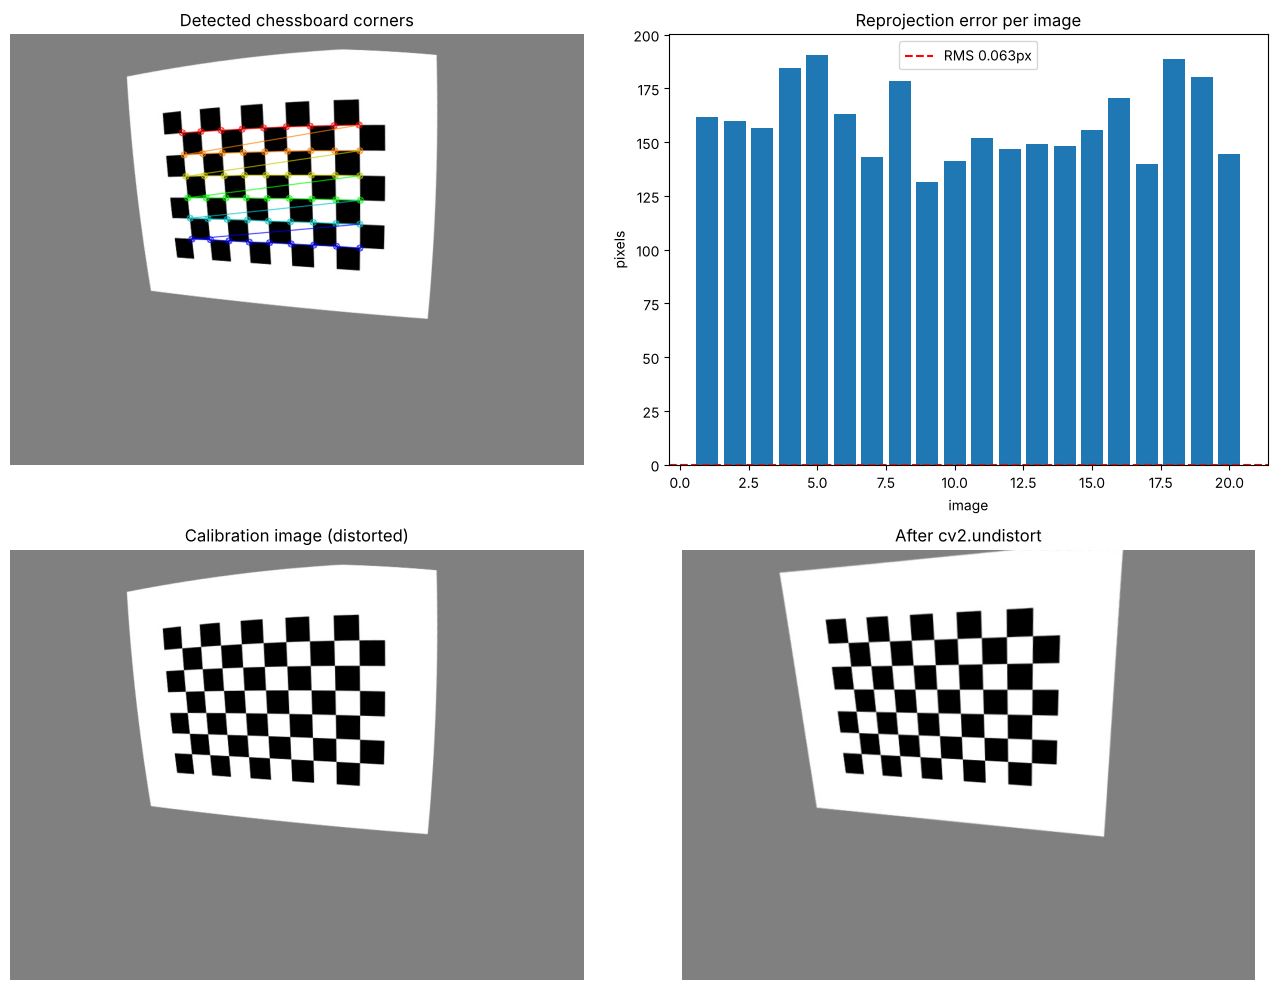

In [8]:
COLS, ROWS = 9, 6
objp = np.zeros((COLS * ROWS, 3), np.float32)
objp[:, :2] = np.mgrid[0:COLS, 0:ROWS].T.reshape(-1, 2)
crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 40, 0.001)

obj_pts, img_pts, kept = [], [], []
for path in sorted(glob.glob("calib/*.jpg")):
    gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    found, corners = cv2.findChessboardCorners(gray, (COLS, ROWS), cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE)
    if found:
        corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), crit)
        obj_pts.append(objp)
        img_pts.append(corners)
        kept.append(path)
img_size = (gray.shape[1], gray.shape[0])
print(f"Chessboard found in {len(kept)}/{len(glob.glob('calib/*.jpg'))} images")

rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(obj_pts, img_pts, img_size, None, None)
np.savez("output/camera_calibration.npz", camera_matrix=K, dist_coeffs=dist, rms=rms)

per_image = []
for o, ip, rv, tv in zip(obj_pts, img_pts, rvecs, tvecs):
    proj, _ = cv2.projectPoints(o, rv, tv, K, dist)
    per_image.append(np.sqrt(np.mean(np.sum((proj - ip) ** 2, axis=2))))

K_gt = np.array([[700.0, 0, 480.0], [0, 700.0, 360.0], [0, 0, 1]])
D_gt = np.array([-0.28, 0.12, 0.0, 0.0, -0.03])
print("RMS reprojection error (px):", round(float(rms), 4))
print("Estimated camera matrix:\n", np.round(K, 3))
print("Known camera matrix:\n", K_gt)
print("Estimated distortion [k1 k2 p1 p2 k3]:", np.round(dist.ravel(), 4))
print("Known distortion      [k1 k2 p1 p2 k3]:", D_gt)

first = cv2.imread(kept[0])
drawn = first.copy()
cv2.drawChessboardCorners(drawn, (COLS, ROWS), img_pts[0], True)
newK, _ = cv2.getOptimalNewCameraMatrix(K, dist, img_size, 0, img_size)
first_fixed = cv2.undistort(first, K, dist, None, newK)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
show(axes[0, 0], drawn, "Detected chessboard corners")
axes[0, 1].bar(range(1, len(per_image) + 1), per_image, color="tab:blue")
axes[0, 1].axhline(rms, color="red", linestyle="--", label=f"RMS {rms:.3f}px")
axes[0, 1].set_title("Reprojection error per image")
axes[0, 1].set_xlabel("image")
axes[0, 1].set_ylabel("pixels")
axes[0, 1].legend()
show(axes[1, 0], first, "Calibration image (distorted)")
show(axes[1, 1], first_fixed, "After cv2.undistort")
plt.tight_layout()
plt.savefig("output/q3_calibration.png", dpi=120)
plt.show()


[ WARN:0@6.290] global cap_v4l.cpp:914 open VIDEOIO(V4L2:/dev/video0): can't open camera by index
[ WARN:0@6.295] global cap.cpp:435 open VIDEOIO(FFMPEG): raised OpenCV exception:

OpenCV(5.0.0) /io/opencv/modules/videoio/src/cap_ffmpeg_impl.hpp:1243: error: (-2:Unspecified error) in function 'bool CvCapture_FFMPEG::open(const char*, int, const cv::Ptr<cv::IStreamReader>&, const cv::VideoCaptureParameters&)'
> VIDEOIO/FFMPEG: Camera index out of range (expected: 'index < device_list->nb_devices'), where
>     'index' is 0
> must be less than
>     'device_list->nb_devices' is 0


[ERROR:0@6.295] global obsensor_uvc_stream_channel.cpp:163 getStreamChannelGroup Camera index out of range


Source: videos/distorted_feed.mp4


Processed 90 frames at 67 FPS


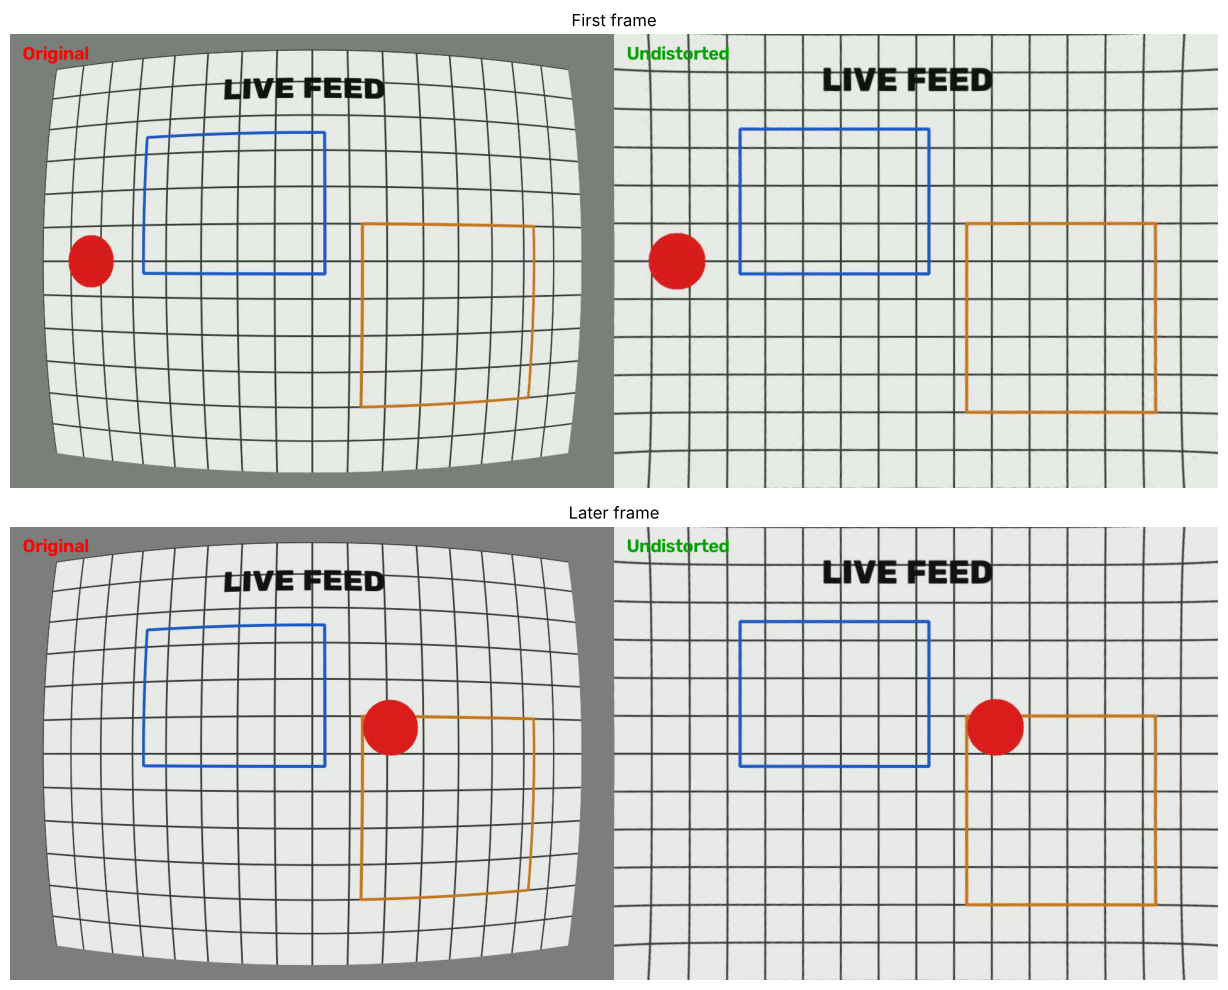

In [9]:
def undistort_stream(source=0, show_window=False, max_frames=None, save_to=None):
    cap = cv2.VideoCapture(source)
    if not cap.isOpened():
        return None
    fw = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    fh = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    new_K, _ = cv2.getOptimalNewCameraMatrix(K, dist, (fw, fh), 0, (fw, fh))
    writer = None
    if save_to:
        writer = cv2.VideoWriter(save_to, cv2.VideoWriter_fourcc(*"mp4v"), 20, (fw * 2, fh))
    samples = []
    count = 0
    start = time.time()
    while max_frames is None or count < max_frames:
        ok, frame = cap.read()
        if not ok:
            break
        fixed = cv2.undistort(frame, K, dist, None, new_K)
        pair = np.hstack([frame, fixed])
        cv2.putText(pair, "Original", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
        cv2.putText(pair, "Undistorted", (fw + 20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 160, 0), 2)
        if writer is not None:
            writer.write(pair)
        if count % 30 == 0:
            samples.append(pair.copy())
        if show_window:
            cv2.imshow("Original | Undistorted (press q to quit)", pair)
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break
        count += 1
    cap.release()
    if writer is not None:
        writer.release()
    return count, count / max(time.time() - start, 1e-6), samples


probe = cv2.VideoCapture(0)
has_camera = probe.isOpened()
probe.release()
source = 0 if has_camera else "videos/distorted_feed.mp4"
print("Source:", "webcam" if has_camera else source)

frames_done, fps, samples = undistort_stream(source, show_window=has_camera, max_frames=300, save_to="output/undistorted_feed.mp4")
if has_camera:
    cv2.destroyAllWindows()
print(f"Processed {frames_done} frames at {fps:.0f} FPS")

fig, axes = plt.subplots(2, 1, figsize=(14, 10))
show(axes[0], samples[0], "First frame")
show(axes[1], samples[-1], "Later frame")
plt.tight_layout()
plt.savefig("output/q3_live_undistort.png", dpi=120)
plt.show()


In [10]:
cap = cv2.VideoCapture("videos/distorted_feed.mp4")
cap.set(cv2.CAP_PROP_POS_FRAMES, 30)
ok, raw = cap.read()
cap.release()
ideal = cv2.imread("images/feed_ideal_frame_30.jpg")
fixed = cv2.undistort(raw, K, dist, None, K_gt)
region = (slice(100, 620), slice(120, 840))
err_raw = np.mean(cv2.absdiff(raw[region], ideal[region]))
err_fixed = np.mean(cv2.absdiff(fixed[region], ideal[region]))
print(f"Mean absolute difference from the distortion-free frame: raw {err_raw:.2f}, undistorted {err_fixed:.2f}")
print(f"Error reduced by {100 * (1 - err_fixed / err_raw):.1f}%")


Mean absolute difference from the distortion-free frame: raw 28.40, undistorted 7.82
Error reduced by 72.4%


## Q4 3D model from images using COLMAP

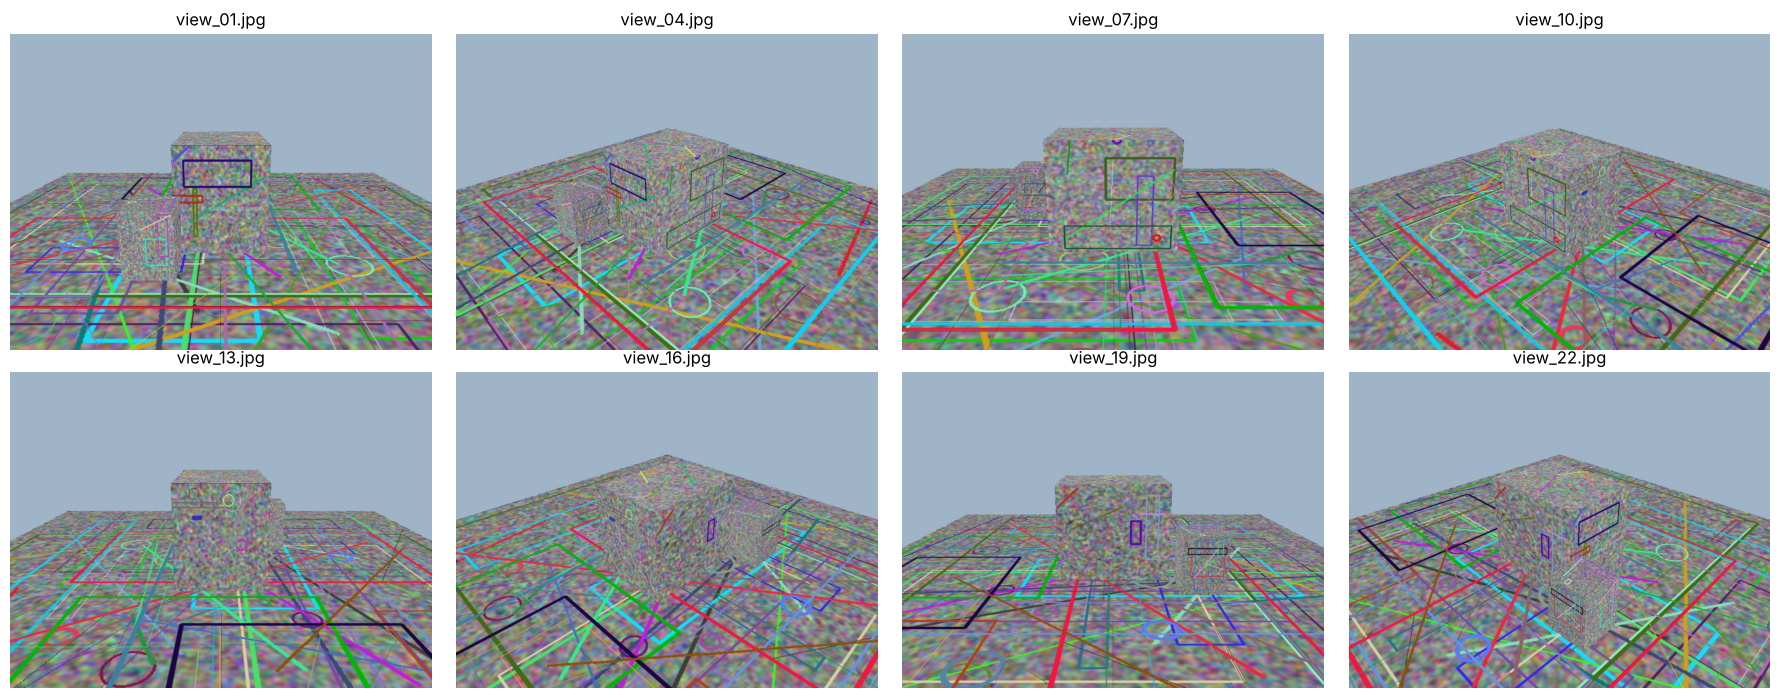

Input images: 24


In [11]:
view_paths = sorted(glob.glob("images/colmap_input/*.jpg"))
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, path in zip(axes.ravel(), view_paths[::3]):
    show(ax, cv2.imread(path), os.path.basename(path))
plt.tight_layout()
plt.savefig("output/q4_input_images.png", dpi=110)
plt.show()
print("Input images:", len(view_paths))


In [12]:
import shutil
import pycolmap

pycolmap.logging.minloglevel = 2
image_dir = "images/colmap_input"
workspace = "output/colmap_workspace"
if os.path.exists(workspace):
    shutil.rmtree(workspace)
os.makedirs(workspace + "/sparse")
database = workspace + "/database.db"

t0 = time.time()
pycolmap.extract_features(database, image_dir, camera_mode=pycolmap.CameraMode.SINGLE)
print(f"Feature detection done in {time.time() - t0:.0f}s")
t1 = time.time()
pycolmap.match_exhaustive(database)
print(f"Feature matching done in {time.time() - t1:.0f}s")
t2 = time.time()
maps = pycolmap.incremental_mapping(database, image_dir, workspace + "/sparse")
rec = max(maps.values(), key=lambda m: m.num_reg_images())
print(f"Camera pose estimation done in {time.time() - t2:.0f}s, reconstructions: {len(maps)}")
print(rec.summary())

cam = next(iter(rec.cameras.values()))
print("Estimated camera:", cam.model.name, np.round(cam.params, 2), "| known focal 800, centre (480, 360)")
rec.write(workspace + "/sparse")
rec.export_PLY("output/sparse_pointcloud_colmap.ply")


Feature detection done in 13s


Feature matching done in 23s


Camera pose estimation done in 5s, reconstructions: 1
Reconstruction:
	num_rigs = 1
	num_cameras = 1
	num_frames = 24
	num_reg_frames = 24
	num_images = 24
	num_points3D = 10237
	num_observations = 45960
	mean_track_length = 4.4896
	mean_observations_per_image = 1915
	mean_reprojection_error = 0.303892
Estimated camera: SIMPLE_RADIAL [800.34 480.   360.    -0.  ] | known focal 800, centre (480, 360)


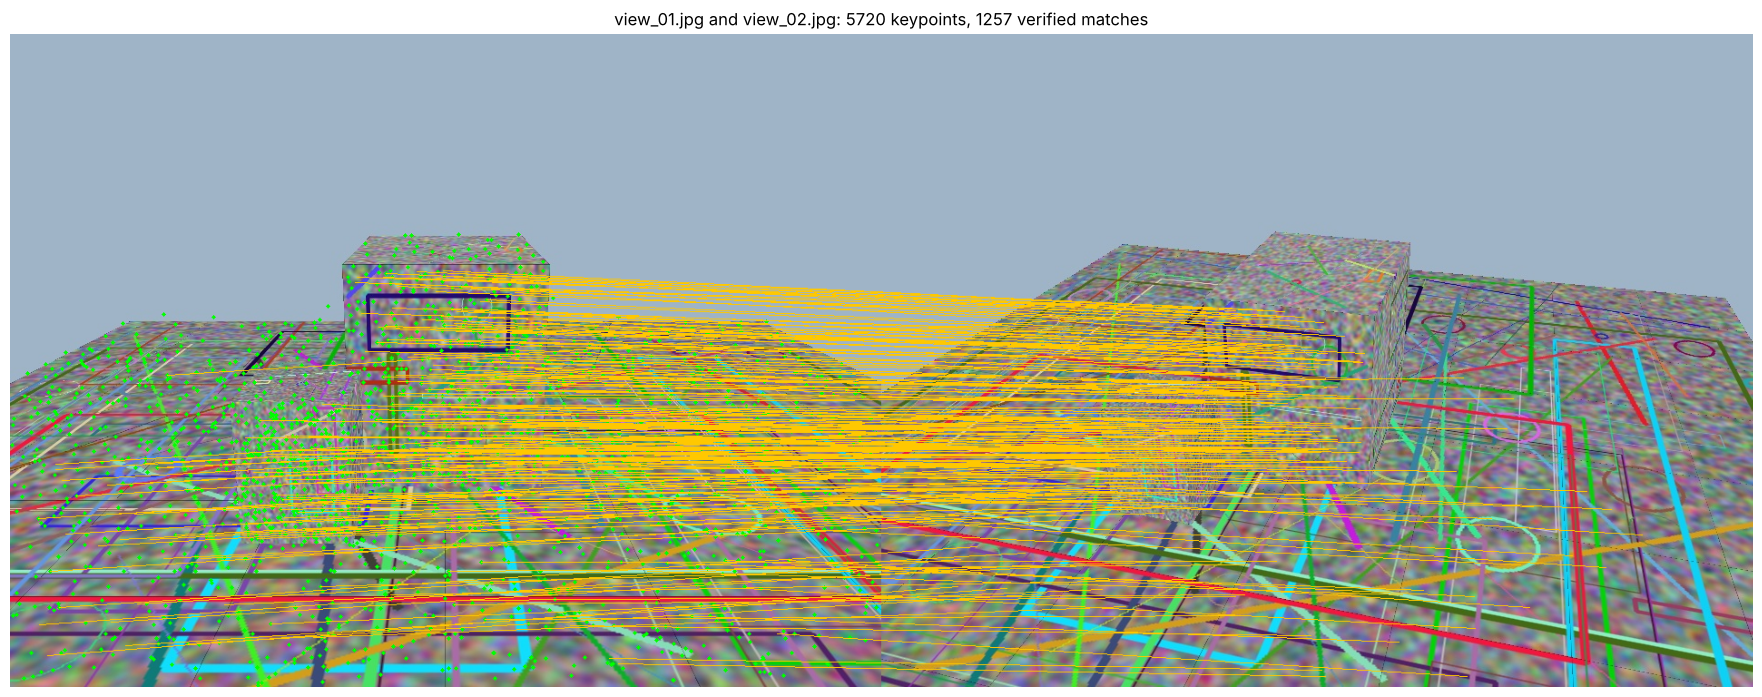

5720 keypoints detected in view_01.jpg and 1257 verified matches with view_02.jpg


In [13]:
by_name = {im.name: im for im in rec.images.values()}
name_a, name_b = "view_01.jpg", "view_02.jpg"
im_a, im_b = by_name[name_a], by_name[name_b]
img_a = cv2.imread(os.path.join(image_dir, name_a))
img_b = cv2.imread(os.path.join(image_dir, name_b))

keypoints = np.array([pt.xy for pt in im_a.points2D])
pairs = []
for p3 in rec.points3D.values():
    seen = {e.image_id: e.point2D_idx for e in p3.track.elements}
    if im_a.image_id in seen and im_b.image_id in seen:
        pairs.append((im_a.points2D[seen[im_a.image_id]].xy, im_b.points2D[seen[im_b.image_id]].xy))

canvas = np.hstack([img_a, img_b])
off = img_a.shape[1]
for x, y in keypoints[::3]:
    cv2.circle(canvas, (int(x), int(y)), 2, (0, 255, 0), -1)
for (xa, ya), (xb, yb) in pairs[::6]:
    cv2.line(canvas, (int(xa), int(ya)), (int(xb) + off, int(yb)), (0, 200, 255), 1)

plt.figure(figsize=(18, 7))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"{name_a} and {name_b}: {len(keypoints)} keypoints, {len(pairs)} verified matches")
plt.tight_layout()
plt.savefig("output/q4_features_matches.png", dpi=110)
plt.show()
print(len(keypoints), "keypoints detected in", name_a, "and", len(pairs), "verified matches with", name_b)


Registered images: 24/24
Camera centre error after similarity alignment: mean 0.09 cm, max 0.16 cm (orbit radius about 5 units)


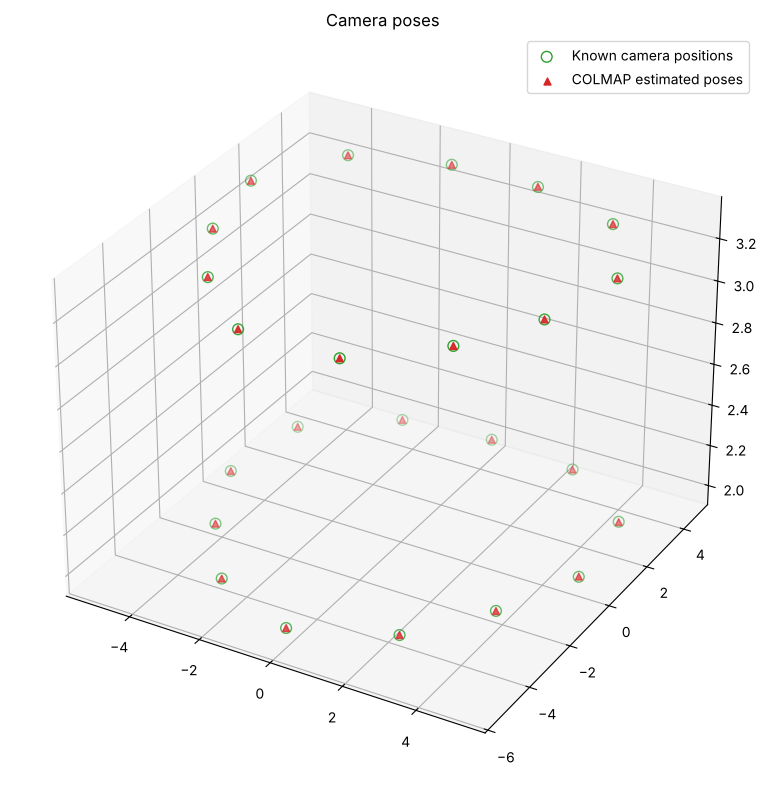

In [14]:
def gt_centre(i):
    th = 2 * np.pi * i / 24
    rad = 5.0 + 0.4 * np.sin(3 * th)
    return np.array([rad * np.cos(th), rad * np.sin(th), 2.0 + 1.3 * (i % 2)])


def fit_similarity(src, dst):
    ms, md = src.mean(axis=0), dst.mean(axis=0)
    A, B = src - ms, dst - md
    U, S, Vt = np.linalg.svd(B.T @ A)
    D = np.eye(3)
    if np.linalg.det(U @ Vt) < 0:
        D[2, 2] = -1
    R = U @ D @ Vt
    s = np.trace(np.diag(S) @ D) / np.sum(A ** 2)
    t = md - s * R @ ms
    return s, R, t


est_c, gt_c = [], []
for im in rec.images.values():
    idx = int(im.name.split("_")[1].split(".")[0]) - 1
    est_c.append(im.projection_center())
    gt_c.append(gt_centre(idx))
est_c, gt_c = np.array(est_c), np.array(gt_c)
s_fit, R_fit, t_fit = fit_similarity(est_c, gt_c)
est_aligned = (s_fit * (R_fit @ est_c.T)).T + t_fit
pose_err = np.linalg.norm(est_aligned - gt_c, axis=1)
print(f"Registered images: {rec.num_reg_images()}/24")
print(f"Camera centre error after similarity alignment: mean {pose_err.mean() * 100:.2f} cm, max {pose_err.max() * 100:.2f} cm (orbit radius about 5 units)")

fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(*gt_c.T, s=60, facecolors="none", edgecolors="tab:green", label="Known camera positions")
ax.scatter(*est_aligned.T, s=25, marker="^", color="tab:red", label="COLMAP estimated poses")
ax.set_title("Camera poses")
ax.legend()
plt.tight_layout()
plt.savefig("output/q4_camera_poses.png", dpi=120)
plt.show()


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Point cloud: 10237 points -> 10089 after outlier removal
Distance to the true surfaces: median 0.07 cm, 90th percentile 0.28 cm, within 5 cm: 100.0%


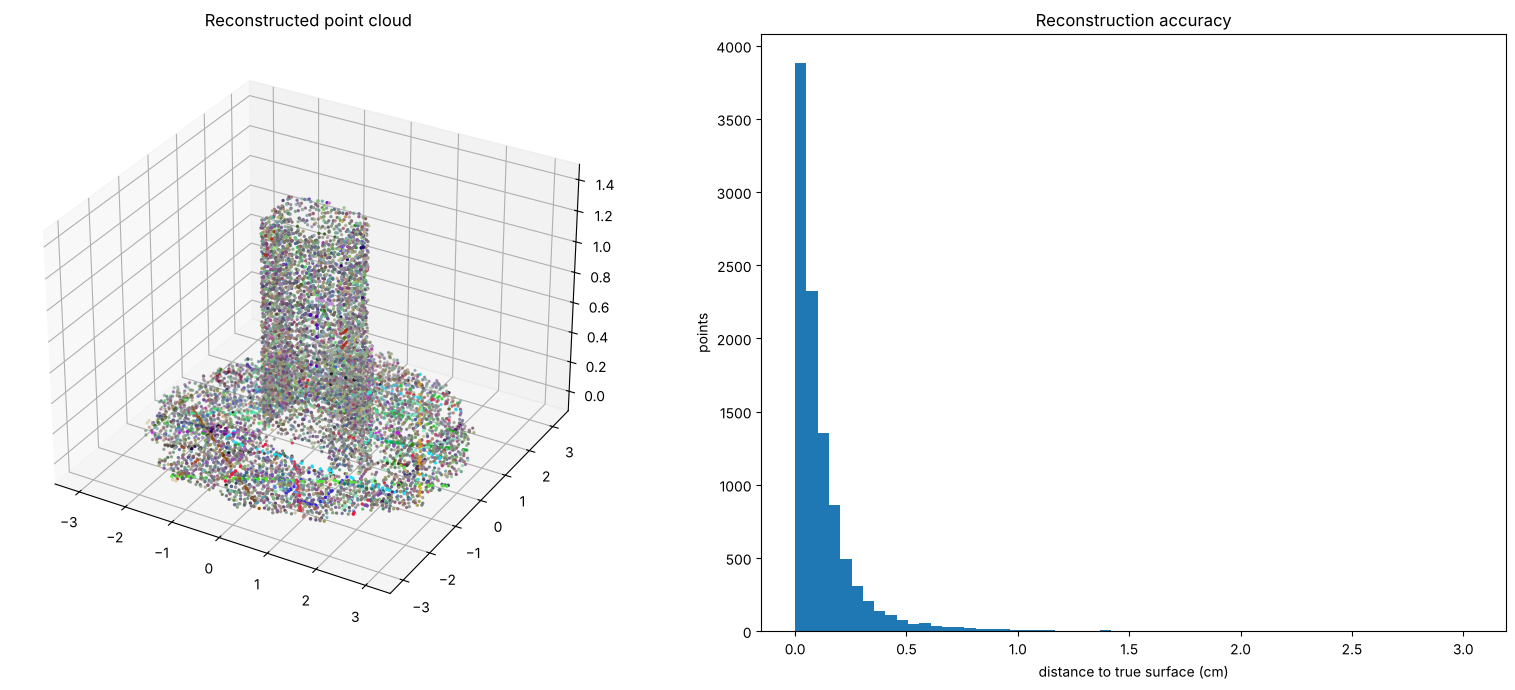

In [15]:
import open3d as o3d

pts_raw = np.array([p.xyz for p in rec.points3D.values()])
col_raw = np.array([p.color for p in rec.points3D.values()]) / 255.0
pts_world = (s_fit * (R_fit @ pts_raw.T)).T + t_fit

pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(pts_world)
pcd.colors = o3d.utility.Vector3dVector(col_raw)
n_before = len(pcd.points)
pcd, _ = pcd.remove_statistical_outlier(nb_neighbors=20, std_ratio=2.0)
pcd, _ = pcd.remove_radius_outlier(nb_points=6, radius=0.35)
o3d.io.write_point_cloud("output/pointcloud.ply", pcd)
print(f"Point cloud: {n_before} points -> {len(pcd.points)} after outlier removal")

boxes = [((-0.8, 0.8), (-0.6, 0.6), 1.4), ((0.9, 1.5), (-1.1, -0.5), 0.8)]


def box_distance(P, xr, yr, h):
    lo = np.array([xr[0], yr[0], 0.0])
    hi = np.array([xr[1], yr[1], h])
    outside = np.linalg.norm(np.maximum(np.maximum(lo - P, P - hi), 0), axis=1)
    inside = np.min(np.minimum(P - lo, hi - P), axis=1)
    return np.where(outside > 0, outside, inside)


P = np.asarray(pcd.points)
d_true = np.minimum(np.abs(P[:, 2]), np.min([box_distance(P, *b) for b in boxes], axis=0))
print(f"Distance to the true surfaces: median {np.median(d_true) * 100:.2f} cm, 90th percentile {np.percentile(d_true, 90) * 100:.2f} cm, within 5 cm: {100 * np.mean(d_true < 0.05):.1f}%")

fig = plt.figure(figsize=(16, 7))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.scatter(*P.T, c=np.asarray(pcd.colors), s=2)
ax1.set_title("Reconstructed point cloud")
ax2 = fig.add_subplot(1, 2, 2)
ax2.hist(d_true * 100, bins=60, color="tab:blue")
ax2.set_xlabel("distance to true surface (cm)")
ax2.set_ylabel("points")
ax2.set_title("Reconstruction accuracy")
plt.tight_layout()
plt.savefig("output/q4_pointcloud.png", dpi=120)
plt.show()


[Open3D WARNING] Write OBJ can not include triangle normals.
Mesh: 20473 vertices, 40350 triangles, watertight: False


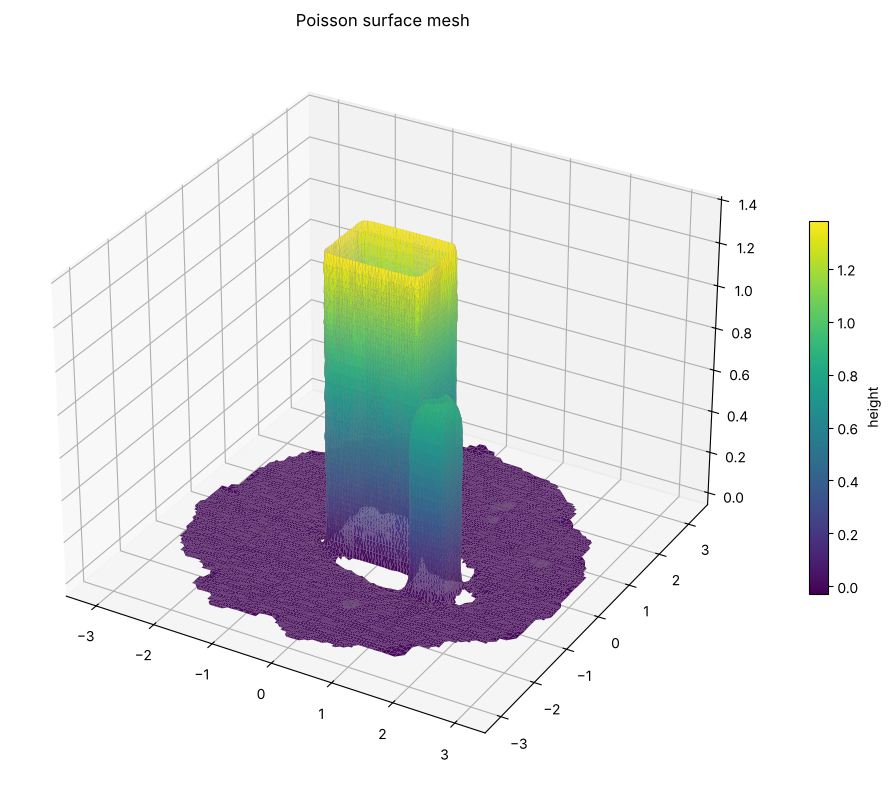

In [16]:
pcd.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=0.4, max_nn=40))
pcd.orient_normals_consistent_tangent_plane(30)
nrm = np.asarray(pcd.normals)
on_ground = np.abs(np.asarray(pcd.points)[:, 2]) < 0.05
if nrm[on_ground, 2].mean() < 0:
    pcd.normals = o3d.utility.Vector3dVector(-nrm)

mesh, density = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(pcd, depth=8)
density = np.asarray(density)
mesh.remove_vertices_by_mask(density < np.quantile(density, 0.06))
mesh = mesh.crop(pcd.get_axis_aligned_bounding_box())
mesh.remove_degenerate_triangles()
mesh.remove_unreferenced_vertices()
mesh.compute_vertex_normals()
o3d.io.write_triangle_mesh("output/mesh_poisson.ply", mesh)
o3d.io.write_triangle_mesh("output/mesh_poisson.obj", mesh)
print(f"Mesh: {len(mesh.vertices)} vertices, {len(mesh.triangles)} triangles, watertight: {mesh.is_watertight()}")

verts = np.asarray(mesh.vertices)
tris = np.asarray(mesh.triangles)
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_trisurf(verts[:, 0], verts[:, 1], verts[:, 2], triangles=tris, cmap="viridis", linewidth=0.05, edgecolor="gray")
ax.set_title("Poisson surface mesh")
fig.colorbar(surf, ax=ax, shrink=0.5, label="height")
plt.tight_layout()
plt.savefig("output/q4_mesh.png", dpi=120)
plt.show()
